# Restaurant Growth Potential Analysis

**Dataset:** SkyCity Auckland Restaurants & Bars

**Objective:** The aim of this project is to understand restaurant performance, identify groups of restaurants with similar characteristics, calculate a Growth Potential Index (GPI), and suggest suitable strategies for improvement.

**Methods used:** Pandas, Matplotlib, Seaborn, StandardScaler, PCA and K-Means clustering. I have also used simple Pandas calculations to create the GPI.

**Project approach:** This project uses unsupervised learning because there is no predefined target column showing which restaurants are ready for growth. The analysis focuses on identifying patterns in the available data rather than predicting a target using regression or classification.

## Importing Libraries

I have imported the libraries required to analyse the restaurant data, create graphs and perform clustering. Each library will be used in the relevant steps of the project.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully")

Libraries imported successfully


## Loading the Dataset

In this step, I load the restaurant dataset into Pandas so that I can inspect the data and begin the analysis.

In [4]:
df = pd.read_csv("SkyCity%20Auckland%20Restaurants%20%26%20Bars.csv")

print("Dataset loaded successfully")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully
Rows: 1696
Columns: 30


,CuisineType,RestaurantID,RestaurantName,Segment,Subregion,GrowthFactor,AOV,MonthlyOrders,InStoreOrders,InStoreRevenue,UberEatsOrders,DoorDashOrders,SelfDeliveryOrders,UberEatsRevenue,DoorDashRevenue,SelfDeliveryRevenue,COGSRate,OPEXRate,CommissionRate,DeliveryRadiusKM,DeliveryCostPerOrder,SD_DeliveryTotalCost,InStoreNetProfit,UberEatsNetProfit,DoorDashNetProfit,SelfDeliveryNetProfit,InStoreShare,UE_share,DD_share,SD_share
0,Burgers,25731,Urban Burgers House,Cafe,North Shore,1.03,43.97,668,197,8662.09,212,118,141,9321.64,5188.46,6199.77,0.208741,0.366172,0.28,11,3.25,458.25,3682.14,1352.45,752.78,2177.19,0.42,0.45,0.25,0.3
1,Burgers,25123,Urban Burgers Diner,QSR,South Auckland,1.05,40.45,1388,259,10476.55,508,282,339,20548.60,11406.90,13712.55,0.248217,0.407613,0.28,16,4.72,1600.08,3605.72,1318.61,731.99,3119.38,0.23,0.45,0.25,0.3
2,Burgers,25177,King Burgers Eatery,Cafe,West Auckland,1.04,40.03,1717,524,20975.72,537,298,358,21496.11,11928.94,14330.74,0.219688,0.407932,0.30,11,3.25,1163.50,7810.95,1555.90,863.42,4172.99,0.44,0.45,0.25,0.3
3,Burgers,25540,Classic Burgers Tavern,QSR,North Shore,1.03,36.28,1083,216,7836.48,390,217,260,14149.20,7872.76,9432.80,0.237291,0.437815,0.33,3,0.89,231.40,2546.02,-72.25,-40.20,2833.26,0.25,0.45,0.25,0.3
4,Burgers,25258,Lucky Burgers Bistro,Cafe,South Auckland,1.05,34.34,1230,261,8962.74,436,242,291,14972.24,8310.28,9992.94,0.221438,0.433457,0.33,9,2.66,774.06,3093.09,226.17,125.53,2674.56,0.27,0.45,0.25,0.3


##  Understanding the Dataset

I checked the column names and data types to understand what information is available and how each column is stored. This also helps me use the correct column names in the next steps.

In [5]:
print(df.columns.tolist())
df.info()

['CuisineType', 'RestaurantID', 'RestaurantName', 'Segment', 'Subregion', 'GrowthFactor', 'AOV', 'MonthlyOrders', 'InStoreOrders', 'InStoreRevenue', 'UberEatsOrders', 'DoorDashOrders', 'SelfDeliveryOrders', 'UberEatsRevenue', 'DoorDashRevenue', 'SelfDeliveryRevenue', 'COGSRate', 'OPEXRate', 'CommissionRate', 'DeliveryRadiusKM', 'DeliveryCostPerOrder', 'SD_DeliveryTotalCost', 'InStoreNetProfit', 'UberEatsNetProfit', 'DoorDashNetProfit', 'SelfDeliveryNetProfit', 'InStoreShare', 'UE_share', 'DD_share', 'SD_share']
<class 'pandas.DataFrame'>
RangeIndex: 1696 entries, 0 to 1695
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   CuisineType            1696 non-null   str    
 1   RestaurantID           1696 non-null   int64  
 2   RestaurantName         1696 non-null   str    
 3   Segment                1696 non-null   str    
 4   Subregion              1696 non-null   str    
 5   GrowthFactor      

## Checking Data Quality

Before starting the analysis, I checked for missing values and duplicate records. This helps me understand whether any data quality issues need attention.

In [6]:
print("Missing values by column:")
print(df.isnull().sum())

print("\nExact duplicate rows:", df.duplicated().sum())
print("Duplicate RestaurantID values:", df["RestaurantID"].duplicated().sum())

Missing values by column:
CuisineType              0
RestaurantID             0
RestaurantName           0
Segment                  0
Subregion                0
GrowthFactor             0
AOV                      0
MonthlyOrders            0
InStoreOrders            0
InStoreRevenue           0
UberEatsOrders           0
DoorDashOrders           0
SelfDeliveryOrders       0
UberEatsRevenue          0
DoorDashRevenue          0
SelfDeliveryRevenue      0
COGSRate                 0
OPEXRate                 0
CommissionRate           0
DeliveryRadiusKM         0
DeliveryCostPerOrder     0
SD_DeliveryTotalCost     0
InStoreNetProfit         0
UberEatsNetProfit        0
DoorDashNetProfit        0
SelfDeliveryNetProfit    0
InStoreShare             0
UE_share                 0
DD_share                 0
SD_share                 0
dtype: int64

Exact duplicate rows: 0
Duplicate RestaurantID values: 0


## Summary Statistics

I used summary statistics to get an overview of the numerical columns, including their average values, minimums and maximums. This gives me a better understanding of the data before analysing it further.

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
RestaurantID,1696.0,25848.500000,489.737345,25001.000000,25424.750000,25848.500000,26272.250000,26696.000000
GrowthFactor,1696.0,1.028255,0.022700,0.990000,1.030000,1.040000,1.050000,1.050000
AOV,1696.0,38.516887,4.459408,29.790000,34.787500,38.340000,42.495000,47.230000
MonthlyOrders,1696.0,1190.527123,422.334848,441.000000,827.000000,1182.000000,1525.000000,2337.000000
InStoreOrders,1696.0,218.980542,149.758619,13.000000,101.000000,178.000000,307.000000,819.000000
InStoreRevenue,1696.0,8422.392730,5851.233352,412.360000,3904.342500,6791.430000,11550.755000,35356.230000
UberEatsOrders,1696.0,471.906250,171.781981,142.000000,331.000000,456.000000,602.000000,937.000000
DoorDashOrders,1696.0,257.155071,92.605301,81.000000,179.750000,249.000000,326.250000,466.000000
SelfDeliveryOrders,1696.0,242.485259,129.950736,60.000000,146.000000,212.000000,306.250000,702.000000
UberEatsRevenue,1696.0,18170.030360,6959.241673,5050.950000,12524.745000,17548.980000,23016.000000,43038.960000


##  Checking Monthly Orders

Here, I compared the total monthly orders with the orders recorded across the four channels. This check helps confirm whether the channel-wise order counts match the overall monthly order count.

In [8]:
df["CalculatedMonthlyOrders"] = (
    df["InStoreOrders"]
    + df["UberEatsOrders"]
    + df["DoorDashOrders"]
    + df["SelfDeliveryOrders"]
)

print("Rows with matching totals:",
      (df["CalculatedMonthlyOrders"] == df["MonthlyOrders"]).sum())

print("Rows with mismatched totals:",
      (df["CalculatedMonthlyOrders"] != df["MonthlyOrders"]).sum())

Rows with matching totals: 1696
Rows with mismatched totals: 0


##  Calculating Total Revenue and Net Profit

I combined the revenue and net profit figures from the available channels to calculate overall totals for each restaurant. These values will help me compare restaurant performance in the following steps.

In [9]:
revenue_columns = [
    "InStoreRevenue",
    "UberEatsRevenue",
    "DoorDashRevenue",
    "SelfDeliveryRevenue"
]

profit_columns = [
    "InStoreNetProfit",
    "UberEatsNetProfit",
    "DoorDashNetProfit",
    "SelfDeliveryNetProfit"
]

df["TotalRevenue"] = df[revenue_columns].sum(axis=1)
df["TotalNetProfit"] = df[profit_columns].sum(axis=1)

df["NetProfitMargin"] = np.where(
    df["TotalRevenue"] > 0,
    df["TotalNetProfit"] / df["TotalRevenue"],
    0
)

df[[
    "RestaurantID", "RestaurantName", "TotalRevenue",
    "TotalNetProfit", "NetProfitMargin"
]].head()

,RestaurantID,RestaurantName,TotalRevenue,TotalNetProfit,NetProfitMargin
0,25731,Urban Burgers House,29371.96,7964.56,0.271162
1,25123,Urban Burgers Diner,56144.60,8775.70,0.156305
2,25177,King Burgers Eatery,68731.51,14403.26,0.209558
3,25540,Classic Burgers Tavern,39291.24,5266.83,0.134046
4,25258,Lucky Burgers Bistro,42238.20,6119.35,0.144877


## Restaurant Distribution by Cuisine

This chart shows how the restaurants are distributed across different cuisine types. It helps me understand which cuisine categories are more common in the dataset.

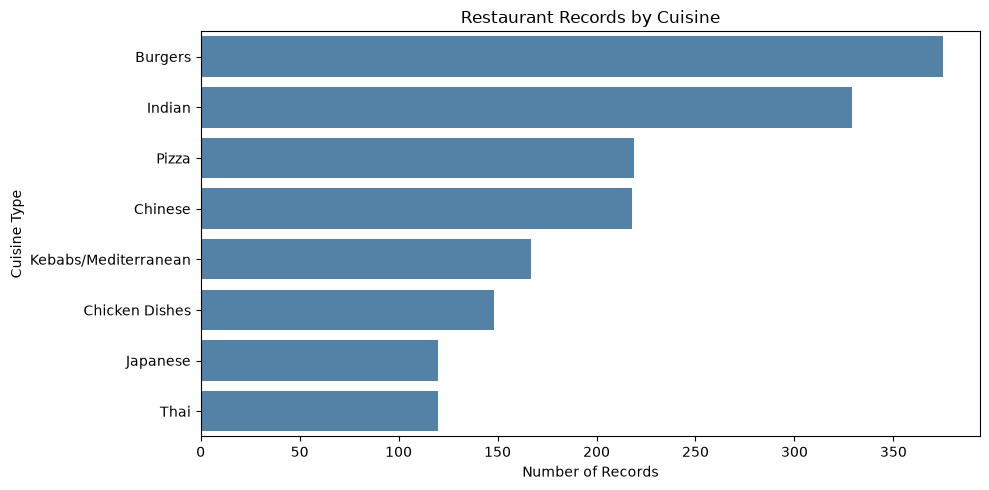

In [10]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y="CuisineType",
              order=df["CuisineType"].value_counts().index, color="steelblue")
plt.title("Restaurant Records by Cuisine")
plt.xlabel("Number of Records")
plt.ylabel("Cuisine Type")
plt.tight_layout()
plt.show()

## Restaurant Distribution by Segment

I used this chart to see how the restaurants are spread across the available business segments. It gives a basic overview of the dataset's composition.

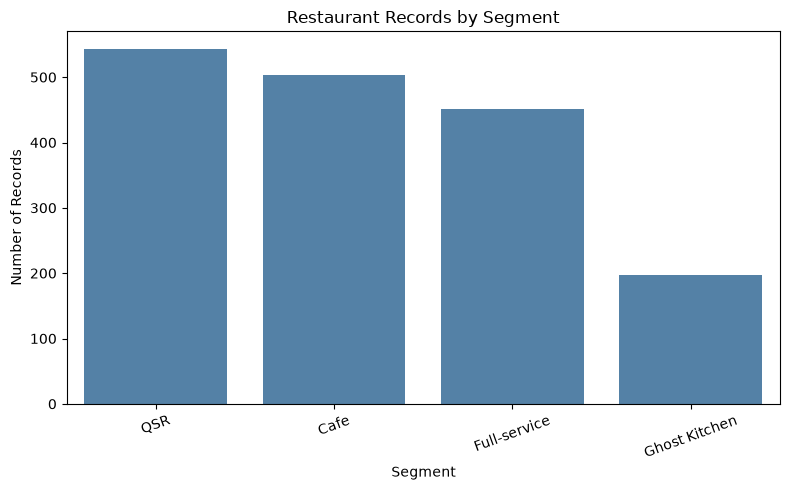

In [11]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Segment",
              order=df["Segment"].value_counts().index, color="steelblue")
plt.title("Restaurant Records by Segment")
plt.xlabel("Segment")
plt.ylabel("Number of Records")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Understanding Growth Factor

This chart shows the distribution of the GrowthFactor values. Values above 1 indicate growth, a value of 1 indicates no change, and values below 1 indicate a decline according to the monthly growth multiplier.

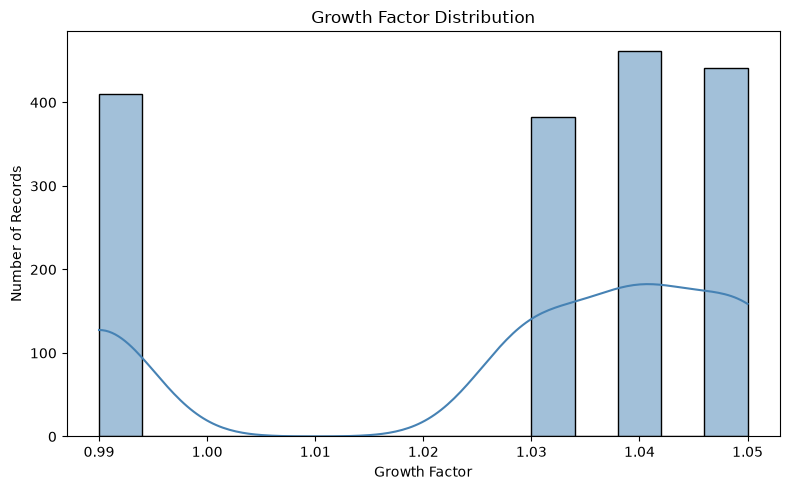

In [12]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="GrowthFactor", bins=15, kde=True, color="steelblue")
plt.title("Growth Factor Distribution")
plt.xlabel("Growth Factor")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

##  Monthly Orders and Growth Factor

I compared monthly order volume with the GrowthFactor to see whether any visible relationship exists between restaurant demand and growth. The chart helps identify patterns, although it does not establish that one factor causes the other.

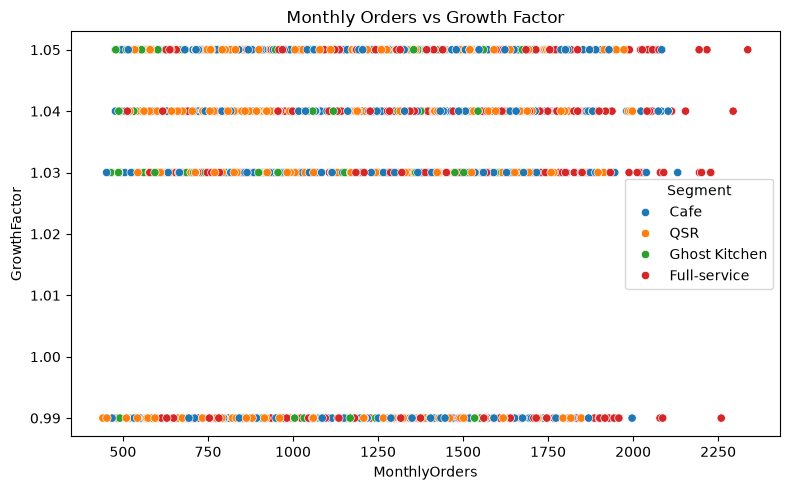

In [13]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="MonthlyOrders", y="GrowthFactor", hue="Segment")
plt.title("Monthly Orders vs Growth Factor")
plt.tight_layout()
plt.show()

## Analysing Cost Rates

I examined COGSRate and OPEXRate to understand the cost burden across restaurants. These values are proportions, so a rate of 0.30 represents 30%.

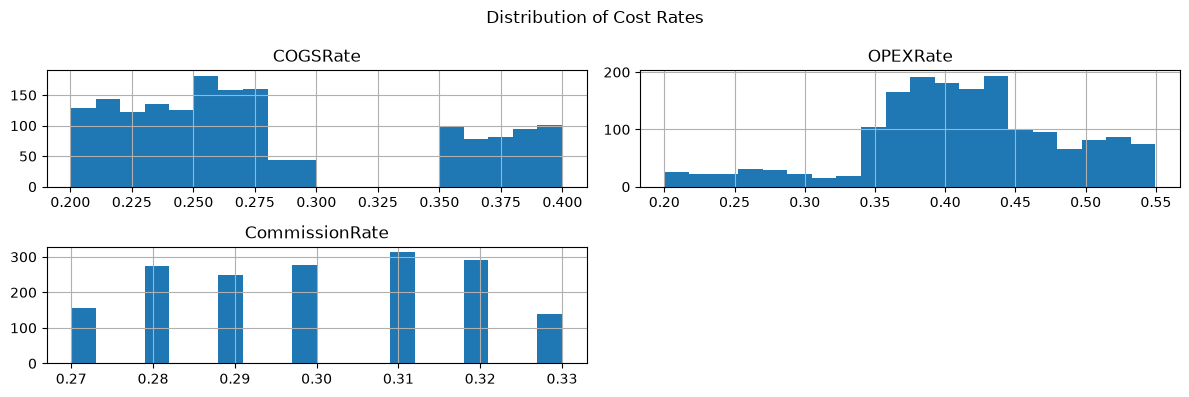

In [14]:
df[["COGSRate", "OPEXRate", "CommissionRate"]].hist(
    figsize=(12, 4), bins=20
)
plt.suptitle("Distribution of Cost Rates")
plt.tight_layout()
plt.show()

## Comparing Profit Margins Across Segments

This chart compares the average profit margin across restaurant segments. It helps show how profitability differs between segments, while keeping in mind that the number of restaurants in each segment may vary.

Segment
Ghost Kitchen    0.220262
Cafe             0.159174
QSR              0.147878
Full-service    -0.059189
Name: NetProfitMargin, dtype: float64


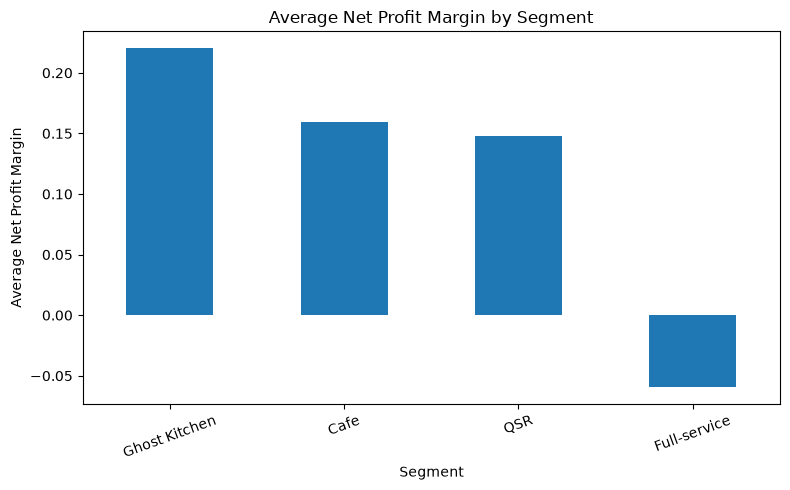

In [15]:
segment_profit = (
    df.groupby("Segment")["NetProfitMargin"]
    .mean()
    .sort_values(ascending=False)
)

print(segment_profit)

segment_profit.plot(kind="bar", figsize=(8, 5))
plt.title("Average Net Profit Margin by Segment")
plt.xlabel("Segment")
plt.ylabel("Average Net Profit Margin")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

##  Calculating Order Shares by Channel

I calculated each channel's share using the total monthly orders as the common denominator. This makes the channel shares easier to compare and helps me understand how much each channel contributes to a restaurant's overall order volume.

In [16]:
df["InStoreTotalShare"] = df["InStoreOrders"] / df["MonthlyOrders"]
df["UberEatsTotalShare"] = df["UberEatsOrders"] / df["MonthlyOrders"]
df["DoorDashTotalShare"] = df["DoorDashOrders"] / df["MonthlyOrders"]
df["SelfDeliveryTotalShare"] = df["SelfDeliveryOrders"] / df["MonthlyOrders"]

channel_share_columns = [
    "InStoreTotalShare",
    "UberEatsTotalShare",
    "DoorDashTotalShare",
    "SelfDeliveryTotalShare"
]

df[channel_share_columns].head()

,InStoreTotalShare,UberEatsTotalShare,DoorDashTotalShare,SelfDeliveryTotalShare
0,0.294910,0.317365,0.176647,0.211078
1,0.186599,0.365994,0.203170,0.244236
2,0.305183,0.312755,0.173559,0.208503
3,0.199446,0.360111,0.200369,0.240074
4,0.212195,0.354472,0.196748,0.236585


## Preparing the GPI Components

I created four components for the Growth Potential Index: growth momentum, cost resilience, channel balance and logistics scalability. These components combine different aspects of restaurant performance into one score. Each component is scaled between 0 and 1, and the four components receive equal weight in the final score.

In [17]:
# Growth momentum: combine the normalized GrowthFactor and MonthlyOrders.
df["GrowthFactorNorm"] = (
    (df["GrowthFactor"] - df["GrowthFactor"].min())
    / (df["GrowthFactor"].max() - df["GrowthFactor"].min())
)

df["MonthlyOrdersNorm"] = (
    (df["MonthlyOrders"] - df["MonthlyOrders"].min())
    / (df["MonthlyOrders"].max() - df["MonthlyOrders"].min())
)

df["GrowthMomentumScore"] = (
    df["GrowthFactorNorm"] + df["MonthlyOrdersNorm"]
) / 2

# Cost resilience: lower combined COGS and OPEX rates are better.
df["CombinedCostRate"] = df["COGSRate"] + df["OPEXRate"]

df["CostResilienceScore"] = (
    (df["CombinedCostRate"].max() - df["CombinedCostRate"])
    / (df["CombinedCostRate"].max() - df["CombinedCostRate"].min())
)

# Channel balance: 1 minus the largest share among the four total-order channels.
df["ChannelBalanceScore"] = 1 - df[channel_share_columns].max(axis=1)

# Logistics scalability: combine delivery radius and self-delivery profit margin.
df["SelfDeliveryProfitMargin"] = np.where(
    df["SelfDeliveryRevenue"] > 0,
    df["SelfDeliveryNetProfit"] / df["SelfDeliveryRevenue"],
    0
)

df["DeliveryRadiusNorm"] = (
    (df["DeliveryRadiusKM"] - df["DeliveryRadiusKM"].min())
    / (df["DeliveryRadiusKM"].max() - df["DeliveryRadiusKM"].min())
)

df["SelfDeliveryMarginNorm"] = (
    (df["SelfDeliveryProfitMargin"] - df["SelfDeliveryProfitMargin"].min())
    / (df["SelfDeliveryProfitMargin"].max() - df["SelfDeliveryProfitMargin"].min())
)

df["LogisticsScalabilityScore"] = (
    df["DeliveryRadiusNorm"] + df["SelfDeliveryMarginNorm"]
) / 2

df[[
    "GrowthMomentumScore", "CostResilienceScore",
    "ChannelBalanceScore", "LogisticsScalabilityScore"
]].head()

,GrowthMomentumScore,CostResilienceScore,ChannelBalanceScore,LogisticsScalabilityScore
0,0.393196,0.761415,0.682635,0.635062
1,0.749736,0.595114,0.634006,0.700507
2,0.753165,0.653091,0.687245,0.585976
3,0.502637,0.555496,0.639889,0.326815
4,0.708070,0.597036,0.645528,0.500040


## Calculating the Growth Potential Index

In this step, I combined the four components to calculate the GPI on a scale of 0 to 100. The score provides a consistent way to compare restaurants within this dataset. It is an analytical index, not a guaranteed prediction of future success.

In [18]:
df["GPI"] = (
    df["GrowthMomentumScore"] * 0.25
    + df["CostResilienceScore"] * 0.25
    + df["ChannelBalanceScore"] * 0.25
    + df["LogisticsScalabilityScore"] * 0.25
) * 100

df[[
    "RestaurantID", "RestaurantName", "GPI",
    "GrowthMomentumScore", "CostResilienceScore",
    "ChannelBalanceScore", "LogisticsScalabilityScore"
]].sort_values("GPI", ascending=False).head(10)

,RestaurantID,RestaurantName,GPI,GrowthMomentumScore,CostResilienceScore,ChannelBalanceScore,LogisticsScalabilityScore
242,26550,Lucky Burgers House,80.316253,0.823840,0.930817,0.579389,0.878605
1453,25298,Classic Pizza Eatery,76.280627,0.888713,0.725991,0.642820,0.793702
419,25124,Top Chicken Dishes Cafe,75.618662,0.896888,0.783330,0.523638,0.820890
33,25886,Urban Burgers Bistro,75.021930,0.694884,0.892940,0.579661,0.833393
1455,26026,Top Pizza House,74.792613,0.845728,0.765852,0.642694,0.737431
293,26359,Classic Burgers Corner,74.679772,0.896888,0.657083,0.639774,0.793445
443,25485,Classic Chicken Dishes Diner,74.087383,0.792194,0.915563,0.438993,0.816746
806,25585,Bombay Kitchen,73.850130,0.752373,0.857501,0.532189,0.811942
212,25916,King Burgers Tavern,73.768008,0.644515,0.919664,0.579310,0.807232
1373,25139,Urban Pizza Grill,73.431171,0.579905,0.980849,0.571237,0.805257


## Selecting Features for Clustering

I selected the numerical and encoded categorical features that describe restaurant growth, demand, costs, channels and logistics. Restaurant names and IDs are excluded because they identify records rather than measure performance. The GPI is also kept out of the clustering inputs so that the groups are not directly formed using the score itself.

In [19]:
numeric_features = [
    "GrowthFactor",
    "AOV",
    "MonthlyOrders",
    "InStoreTotalShare",
    "UberEatsTotalShare",
    "DoorDashTotalShare",
    "SelfDeliveryTotalShare",
    "COGSRate",
    "OPEXRate",
    "CommissionRate",
    "DeliveryRadiusKM",
    "DeliveryCostPerOrder",
    "SD_DeliveryTotalCost",
    "NetProfitMargin"
]

categorical_features = ["CuisineType", "Segment", "Subregion"]

# Encode categories using Pandas.
df_encoded = pd.get_dummies(
    df[numeric_features + categorical_features],
    columns=categorical_features,
    dtype=int
)

print("Number of clustering features:", df_encoded.shape[1])
df_encoded.head()

Number of clustering features: 30


,GrowthFactor,AOV,MonthlyOrders,InStoreTotalShare,UberEatsTotalShare,DoorDashTotalShare,SelfDeliveryTotalShare,COGSRate,OPEXRate,CommissionRate,DeliveryRadiusKM,DeliveryCostPerOrder,SD_DeliveryTotalCost,NetProfitMargin,CuisineType_Burgers,CuisineType_Chicken Dishes,CuisineType_Chinese,CuisineType_Indian,CuisineType_Japanese,CuisineType_Kebabs/Mediterranean,CuisineType_Pizza,CuisineType_Thai,Segment_Cafe,Segment_Full-service,Segment_Ghost Kitchen,Segment_QSR,Subregion_CBD,Subregion_North Shore,Subregion_South Auckland,Subregion_West Auckland
0,1.03,43.97,668,0.294910,0.317365,0.176647,0.211078,0.208741,0.366172,0.28,11,3.25,458.25,0.271162,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0
1,1.05,40.45,1388,0.186599,0.365994,0.203170,0.244236,0.248217,0.407613,0.28,16,4.72,1600.08,0.156305,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0
2,1.04,40.03,1717,0.305183,0.312755,0.173559,0.208503,0.219688,0.407932,0.30,11,3.25,1163.50,0.209558,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1
3,1.03,36.28,1083,0.199446,0.360111,0.200369,0.240074,0.237291,0.437815,0.33,3,0.89,231.40,0.134046,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0
4,1.05,34.34,1230,0.212195,0.354472,0.196748,0.236585,0.221438,0.433457,0.33,9,2.66,774.06,0.144877,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0


## Scaling the Features

I used StandardScaler to bring the selected features onto a comparable scale. This is important because K-Means uses distances, and features with larger numerical values could otherwise have a greater influence on the clustering results.

In [20]:
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df_encoded)

print("Scaled feature matrix shape:", scaled_features.shape)

Scaled feature matrix shape: (1696, 30)


## Reducing Dimensions with PCA

I used PCA to reduce the scaled features to two dimensions for visualisation. This makes it easier to display the clusters on a graph. The actual K-Means clustering is performed on the scaled feature data.

In [21]:
pca = PCA(n_components=2)
pca_features = pca.fit_transform(scaled_features)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance shown in 2 components:",
      pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.16795363 0.12786186]
Total variance shown in 2 components: 0.2958154824963722


## Applying K-Means Clustering

I applied K-Means with five clusters to group restaurants with similar characteristics. The number of clusters was selected for this project to explore five possible restaurant groups. I then review the cluster profiles to understand the differences between them.

In [22]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(scaled_features)

print(df["Cluster"].value_counts().sort_index())

Cluster
0    205
1    464
2    452
3    188
4    387
Name: count, dtype: int64


## Visualising the Clusters

This plot displays the restaurant groups using the two PCA dimensions. It provides a visual overview of how the observations are arranged across the clusters.

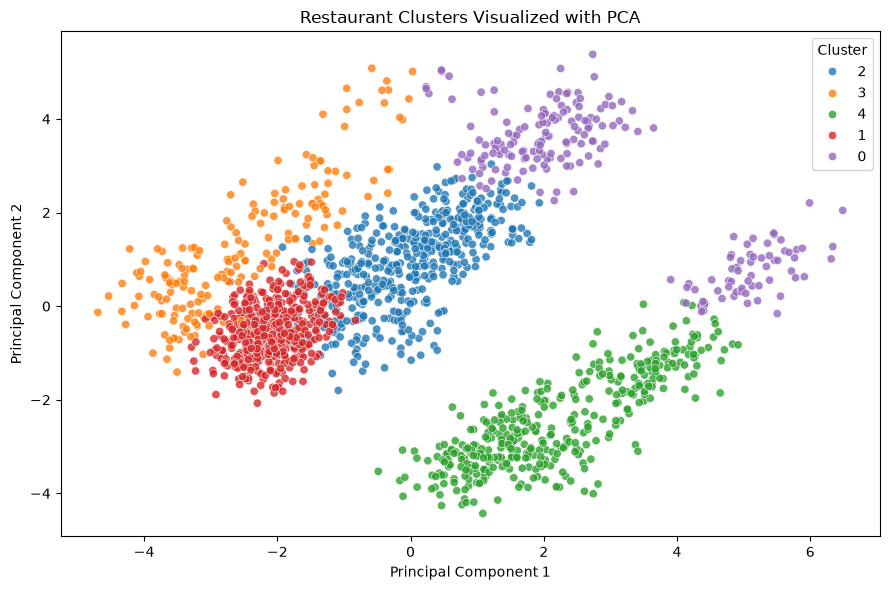

In [23]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=pca_features[:, 0],
    y=pca_features[:, 1],
    hue=df["Cluster"].astype(str),
    palette="tab10",
    alpha=0.8
)
plt.title("Restaurant Clusters Visualized with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

## Reviewing Cluster Profiles

I compared the average business measures for each cluster to understand how the groups differ in terms of orders, growth, costs and profitability. These results help me describe the clusters based on their observed performance.

In [24]:
cluster_profile = df.groupby("Cluster").agg(
    RestaurantCount=("RestaurantID", "count"),
    AverageGrowthFactor=("GrowthFactor", "mean"),
    AverageOrders=("MonthlyOrders", "mean"),
    AverageAOV=("AOV", "mean"),
    AverageCOGSRate=("COGSRate", "mean"),
    AverageOPEXRate=("OPEXRate", "mean"),
    AverageDeliveryRadius=("DeliveryRadiusKM", "mean"),
    AverageProfitMargin=("NetProfitMargin", "mean"),
    AverageGPI=("GPI", "mean")
).round(3)

cluster_profile

,RestaurantCount,AverageGrowthFactor,AverageOrders,AverageAOV,AverageCOGSRate,AverageOPEXRate,AverageDeliveryRadius,AverageProfitMargin,AverageGPI
Cluster,,,,,,,,,
0,205,1.029,1333.502,38.474,0.281,0.426,10.717,0.139,55.292
1,464,1.029,1055.164,38.644,0.242,0.401,10.539,0.124,54.936
2,452,1.029,1233.465,38.702,0.239,0.400,10.458,0.167,58.252
3,188,1.028,1043.059,38.478,0.277,0.270,10.814,0.219,61.803
4,387,1.027,1298.576,38.189,0.375,0.500,10.522,-0.066,41.370


In [31]:
display(cluster_profile)

,RestaurantCount,AverageGrowthFactor,AverageOrders,AverageAOV,AverageCOGSRate,AverageOPEXRate,AverageDeliveryRadius,AverageProfitMargin,AverageGPI
Cluster,,,,,,,,,
0,205,1.029,1333.502,38.474,0.281,0.426,10.717,0.139,55.292
1,464,1.029,1055.164,38.644,0.242,0.401,10.539,0.124,54.936
2,452,1.029,1233.465,38.702,0.239,0.400,10.458,0.167,58.252
3,188,1.028,1043.059,38.478,0.277,0.270,10.814,0.219,61.803
4,387,1.027,1298.576,38.189,0.375,0.500,10.522,-0.066,41.370


## Suggesting Business Strategies

I used simple business rules to assign a strategy recommendation to each restaurant. The recommendations consider factors such as the GPI, profit margin, growth, costs and delivery channel mix. These rules provide initial guidance and would need further review before being used for actual business decisions.

In [36]:

def recommend_strategy(row):
    if (
        row["GPI"] >= 70
        and row["NetProfitMargin"] > 0
        and row["GrowthFactor"] > 1
        and row["CostResilienceScore"] >= 0.5
    ):
        return "Expand selectively"

    elif (
        row["UE_share"] + row["DD_share"] >= 0.70
        and row["SD_share"] < 0.20
    ):
        return "Rebalance channels"

    elif row["CombinedCostRate"] >= df["CombinedCostRate"].median():
        return "Optimize costs"

    else:
        return "Hold / stabilize"


df["StrategyRecommendation"] = df.apply(
    recommend_strategy, axis=1
)

df[[
    "RestaurantID",
    "RestaurantName",
    "GPI",
    "NetProfitMargin",
    "GrowthFactor",
    "StrategyRecommendation"
]].head(10)

,RestaurantID,RestaurantName,GPI,NetProfitMargin,GrowthFactor,StrategyRecommendation
0,25731,Urban Burgers House,61.807696,0.271162,1.03,Hold / stabilize
1,25123,Urban Burgers Diner,66.984082,0.156305,1.05,Optimize costs
2,25177,King Burgers Eatery,66.986936,0.209558,1.04,Hold / stabilize
3,25540,Classic Burgers Tavern,50.620937,0.134046,1.03,Optimize costs
4,25258,Lucky Burgers Bistro,61.266861,0.144877,1.05,Optimize costs
5,26138,King Burgers Kitchen,56.598930,0.150247,1.03,Optimize costs
6,25396,Urban Burgers Eatery,61.988548,0.235468,1.05,Hold / stabilize
7,25087,Urban Burgers Tavern,55.969633,0.181947,0.99,Hold / stabilize
8,25125,Classic Burgers Tavern,44.356578,0.170745,0.99,Optimize costs
9,25762,Lucky Burgers Cafe,58.767359,0.181670,1.05,Hold / stabilize


## Naming the Restaurant Groups

After reviewing the cluster profiles, I assigned descriptive names to the groups based on their observed characteristics. These labels make the results easier to understand and communicate.

In [37]:

cluster_labels = {
    0: "High-Volume Moderate-Margin",
    1: "Stable Moderate-Margin",
    2: "High-Volume Strong-Margin",
    3: "High-Margin Lower-Cost",
    4: "High-Cost Negative-Margin"
}

df["ClusterLabel"] = df["Cluster"].map(cluster_labels)

df[[
    "RestaurantID",
    "RestaurantName",
    "Cluster",
    "ClusterLabel",
    "GPI",
    "StrategyRecommendation"
]].head(10)

,RestaurantID,RestaurantName,Cluster,ClusterLabel,GPI,StrategyRecommendation
0,25731,Urban Burgers House,2,High-Volume Strong-Margin,61.807696,Hold / stabilize
1,25123,Urban Burgers Diner,2,High-Volume Strong-Margin,66.984082,Optimize costs
2,25177,King Burgers Eatery,2,High-Volume Strong-Margin,66.986936,Hold / stabilize
3,25540,Classic Burgers Tavern,2,High-Volume Strong-Margin,50.620937,Optimize costs
4,25258,Lucky Burgers Bistro,2,High-Volume Strong-Margin,61.266861,Optimize costs
5,26138,King Burgers Kitchen,2,High-Volume Strong-Margin,56.598930,Optimize costs
6,25396,Urban Burgers Eatery,2,High-Volume Strong-Margin,61.988548,Hold / stabilize
7,25087,Urban Burgers Tavern,3,High-Margin Lower-Cost,55.969633,Hold / stabilize
8,25125,Classic Burgers Tavern,2,High-Volume Strong-Margin,44.356578,Optimize costs
9,25762,Lucky Burgers Cafe,2,High-Volume Strong-Margin,58.767359,Hold / stabilize


## Creating the Restaurant Scorecard

I combined the main restaurant details, cluster assignments, GPI scores and strategy recommendations into one scorecard. This table provides a single view of the results and can be used for further analysis or reporting.

In [38]:
scorecard_columns = [
    "RestaurantID",
    "RestaurantName",
    "CuisineType",
    "Segment",
    "Subregion",
    "Cluster",
    "ClusterLabel",
    "GPI",
    "GrowthFactor",
    "MonthlyOrders",
    "AOV",
    "TotalRevenue",
    "TotalNetProfit",
    "NetProfitMargin",
    "StrategyRecommendation"
]

scorecard = df[scorecard_columns].sort_values("GPI", ascending=False)

scorecard.head(20)

,RestaurantID,RestaurantName,CuisineType,Segment,Subregion,Cluster,ClusterLabel,GPI,GrowthFactor,MonthlyOrders,AOV,TotalRevenue,TotalNetProfit,NetProfitMargin,StrategyRecommendation
242,26550,Lucky Burgers House,Burgers,Ghost Kitchen,South Auckland,3,High-Margin Lower-Cost,80.316253,1.05,1669,36.91,61602.79,17896.53,0.290515,Expand selectively
1453,25298,Classic Pizza Eatery,Pizza,QSR,South Auckland,0,High-Volume Moderate-Margin,76.280627,1.05,1915,46.82,89660.30,20217.63,0.225491,Expand selectively
419,25124,Top Chicken Dishes Cafe,Chicken Dishes,QSR,South Auckland,2,High-Volume Strong-Margin,75.618662,1.05,1946,37.23,72449.58,16161.91,0.223078,Expand selectively
33,25886,Urban Burgers Bistro,Burgers,Ghost Kitchen,South Auckland,3,High-Margin Lower-Cost,75.021930,1.05,1180,35.87,42326.60,10178.25,0.240469,Expand selectively
1455,26026,Top Pizza House,Pizza,QSR,South Auckland,0,High-Volume Moderate-Margin,74.792613,1.05,1752,38.89,68135.28,17709.59,0.259918,Expand selectively
293,26359,Classic Burgers Corner,Burgers,QSR,South Auckland,2,High-Volume Strong-Margin,74.679772,1.05,1946,46.28,90060.88,17611.86,0.195555,Expand selectively
443,25485,Classic Chicken Dishes Diner,Chicken Dishes,Ghost Kitchen,South Auckland,3,High-Margin Lower-Cost,74.087383,1.05,1549,36.15,55996.35,12293.75,0.219546,Expand selectively
806,25585,Bombay Kitchen,Indian,Ghost Kitchen,South Auckland,3,High-Margin Lower-Cost,73.850130,1.05,1398,33.71,47126.58,11052.95,0.234537,Expand selectively
212,25916,King Burgers Tavern,Burgers,Ghost Kitchen,West Auckland,3,High-Margin Lower-Cost,73.768008,1.04,1305,42.82,55880.10,14367.66,0.257116,Expand selectively
1373,25139,Urban Pizza Grill,Pizza,Ghost Kitchen,South Auckland,3,High-Margin Lower-Cost,73.431171,1.05,744,32.66,24299.04,7434.44,0.305956,Expand selectively


## Comparing GPI Across Clusters

I compared the GPI scores across the different clusters to understand how their growth potential scores vary. This comparison helps connect the clustering results with the index calculated earlier.

Cluster
3    61.802728
2    58.251914
0    55.291794
1    54.936293
4    41.369701
Name: GPI, dtype: float64


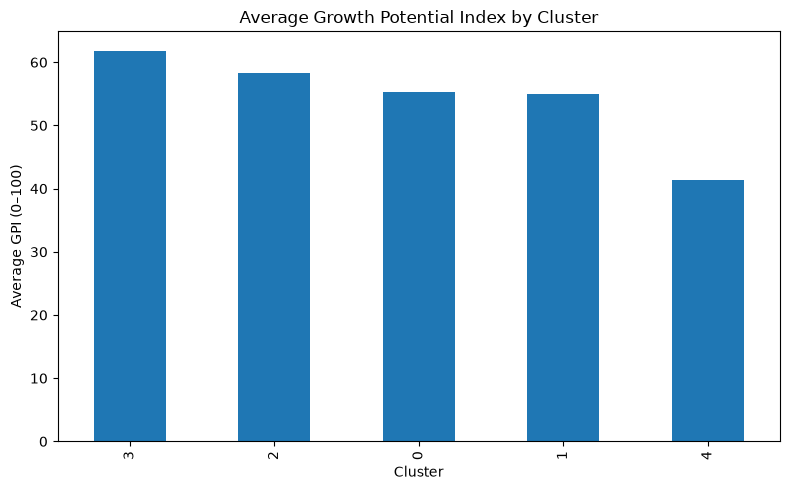

In [39]:
cluster_gpi = df.groupby("Cluster")["GPI"].mean().sort_values(ascending=False)

print(cluster_gpi)

cluster_gpi.plot(kind="bar", figsize=(8, 5))
plt.title("Average Growth Potential Index by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average GPI (0–100)")
plt.tight_layout()
plt.show()

## Saving the Results

I saved the restaurant scorecard and cluster profile as CSV files. These files can be used later while preparing the research paper, executive summary or dashboard.

In [40]:
scorecard.to_csv("Restaurant_Growth_Potential_Scorecard.csv", index=False)
cluster_profile.to_csv("Restaurant_Cluster_Profile.csv")

print("Files saved successfully")

Files saved successfully


## Project Conclusion



- **Exploratory analysis:** Summarise the main patterns found in cuisine types, restaurant segments, growth, orders and costs.
- **Clustering:** Explain how the restaurant groups differ using the cluster profile table.
- **Growth Potential Index:** Describe how the four components were combined into an equally weighted score.
- **Business recommendations:** Report the number of restaurants assigned to each strategy and explain the main patterns observed.
- **Limitations:** Mention that the analysis uses the available dataset, while the GPI weights and recommendation rules are assumptions that may need further validation.